# Step 3: Create multi-panel subject images
This step of the RRN-to-Zooniverse pipeline creates two clean multipanel images:  
- shoing two RGB image scalings
- the individual single band images 

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import seaborn as sns
import os
import pandas as pd
from tqdm import trange

In [2]:
def make_color_subject(source_id, cutout_loc, save_path = '', panel1_type='arcsinh_desaturated', panel2_type='mtf_desaturated'):
    """
    Make a color subject image (2 panel) from the cutout data.
    
    Parameters:
    ----------
        id_field: str 
            The ID field of the cutout data.
        save_path: str
            The path to save the figure. If empty, the figure will not be saved. If given, the figure won't be shown inline.
        panel1_type: str 
            The type of the first panel ('arcsinh_desaturated' or 'arcsinh').
        panel2_type: str 
            The type of the second panel ('mtf_desaturated' or 'mtf).
    """
    if panel1_type not in color_img_types or panel2_type not in color_img_types:
        raise ValueError("Invalid panel type. Choose from 'arcsinh_desaturated', 'arcsinh', 'mtf_desaturated', or 'mtf'.")
    
    # Get the color image locations
    color_img_locs = cutout_loc + source_id
    
    # Load the images
    panel1 = np.array(Image.open(color_img_locs+f'_{panel1_type}.png'))
    panel2 = np.array(Image.open(color_img_locs+f'_{panel2_type}.png'))

    # Create two-paneled figure
    fig, ax = plt.subplots(figsize=(5,2.5), sharex=True, sharey=True, ncols=2)
    ax[0].imshow(panel1)
    ax[1].imshow(panel2)

    ax[0].set_xticks([])
    ax[0].set_yticks([])
    
    if save_path:
        if 'png' in save_path:
                plt.savefig(save_path, bbox_inches='tight', transparent=True)
        else:
                plt.savefig(save_path, bbox_inches='tight', pil_kwargs={'quality': 95})
        plt.close(fig)

    plt.show()

In [3]:

subject_plots = lambda: sns.set(context='paper', font_scale=1.0, style='white',
                             rc={'figure.figsize':(4,3), 'figure.dpi':300, 'figure.facecolor':'w', 
                                 'figure.subplot.wspace':0.01, 'figure.subplot.hspace':0.01, 
                                 'figure.subplot.left':0, 'figure.subplot.right':1,
                                 'figure.subplot.top':1, 'figure.subplot.bottom':0,
                                 'grid.alpha':0.15, 'axes.axisbelow':True, 
                                 'axes.grid' : False,
                                 'image.cmap':'gray',
                                })
subject_plots()

In [4]:
color_img_types = ['arcsinh', 'arcsinh_desaturated', 'mtf', 'mtf_desaturated']

cutout_save_dir = '/teams/gz-roman/10012026-test-cutouts/'
colour_cutout_save_dir = '/teams/gz-roman/10012026-test-colour_cutouts/' #where the individual color cutouts are saved

subject_png_save_dir = '/teams/gz-roman/10012026-test-subjects_pngs/' #where to save the individual subject (2 panel) images
if not os.path.isdir(subject_png_save_dir):
    os.makedirs(subject_png_save_dir)

In [5]:
bands = ['f106', 'f129', 'f158']

catalog_name = '10012026-TEST-full_catalog_file_locs_'
for i in range(len(bands)):
    if bands[i] == bands[-1]:
        catalog_name = catalog_name + bands[i]
    else:
        catalog_name = catalog_name + bands[i]+'_'
print(catalog_name)

cat_df = pd.read_parquet('/teams/gz-roman/'+catalog_name+'.parquet')
print(cat_df.columns)

10012026-TEST-full_catalog_file_locs_f106_f129_f158
Index(['id_str', 'asdf_loc_f106', 'asdf_loc_f129', 'asdf_loc_f158',
       'ra_centroid_f106', 'dec_centroid_f106', 'kron_abmag_f106',
       'kron_radius_f106', 'fluxfrac_radius_50_f106', 'segment_area_f106',
       'is_extended_f106', 'semimajor_f106', 'semiminor_f106',
       'ra_centroid_f129', 'dec_centroid_f129', 'kron_abmag_f129',
       'kron_radius_f129', 'fluxfrac_radius_50_f129', 'segment_area_f129',
       'is_extended_f129', 'semimajor_f129', 'semiminor_f129',
       'ra_centroid_f158', 'dec_centroid_f158', 'kron_abmag_f158',
       'kron_radius_f158', 'fluxfrac_radius_50_f158', 'segment_area_f158',
       'is_extended_f158', 'semimajor_f158', 'semiminor_f158', 'skycell'],
      dtype='str')


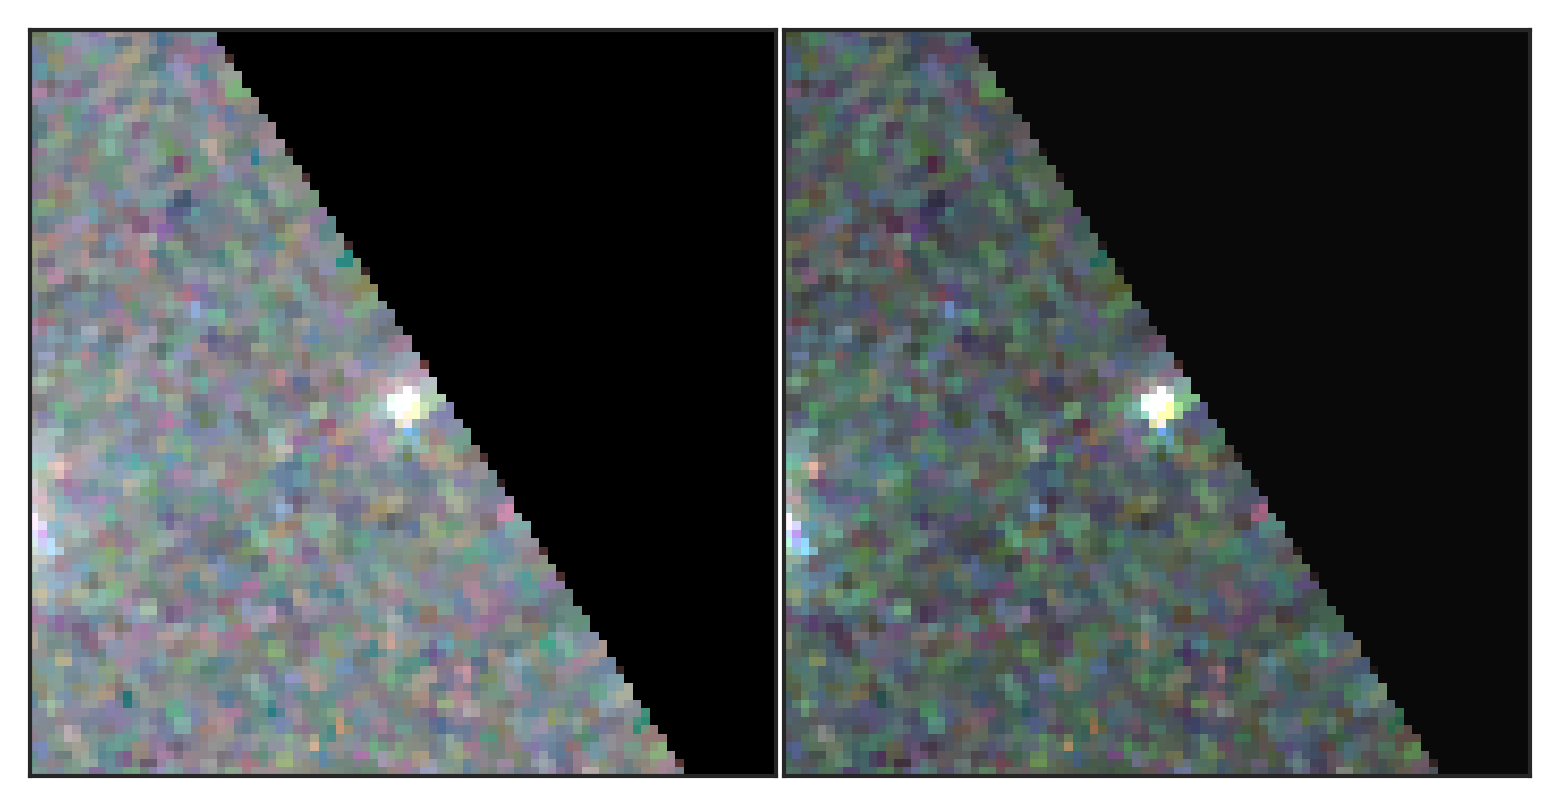

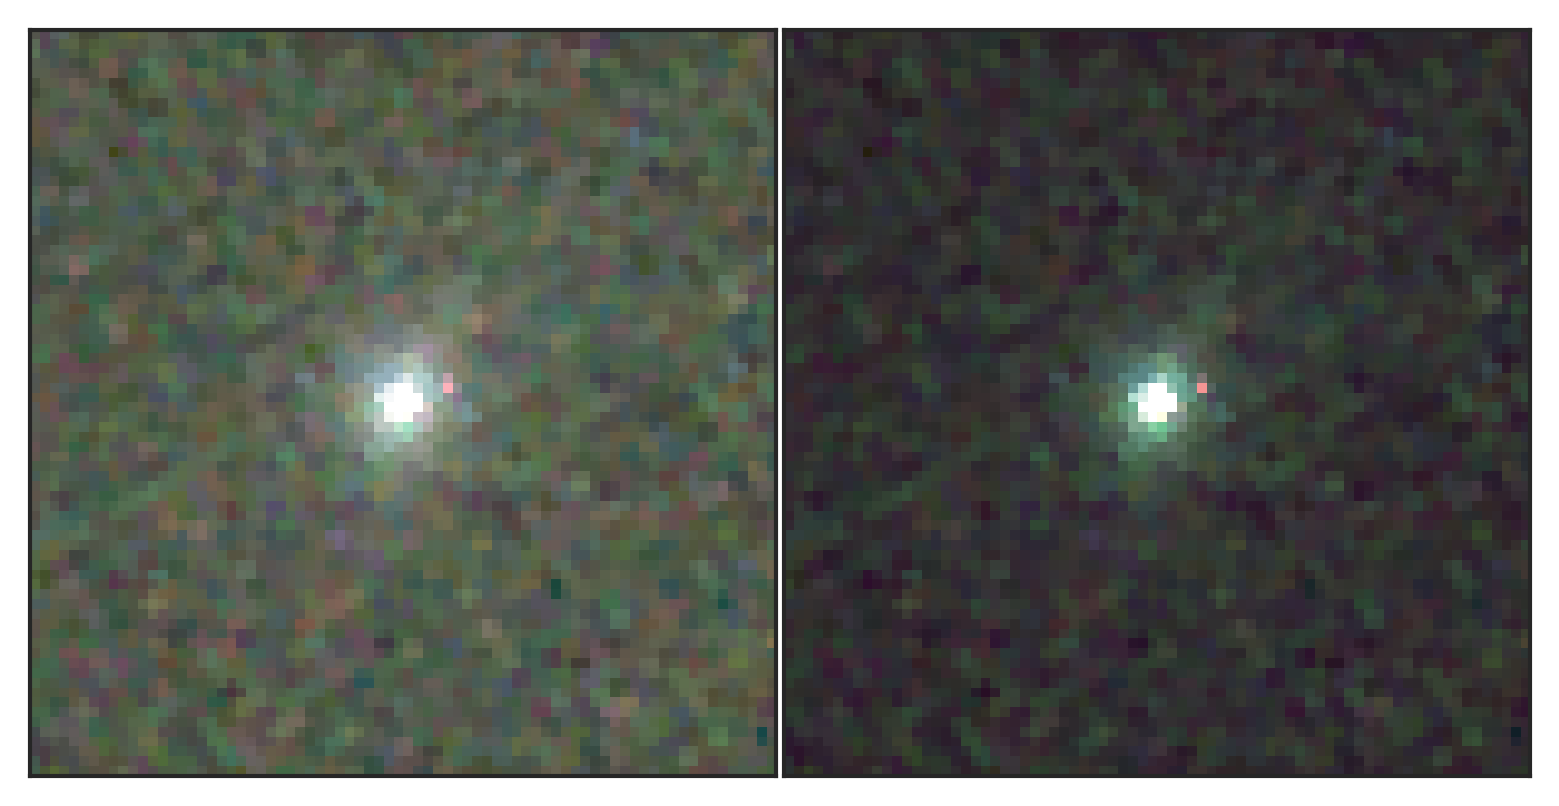

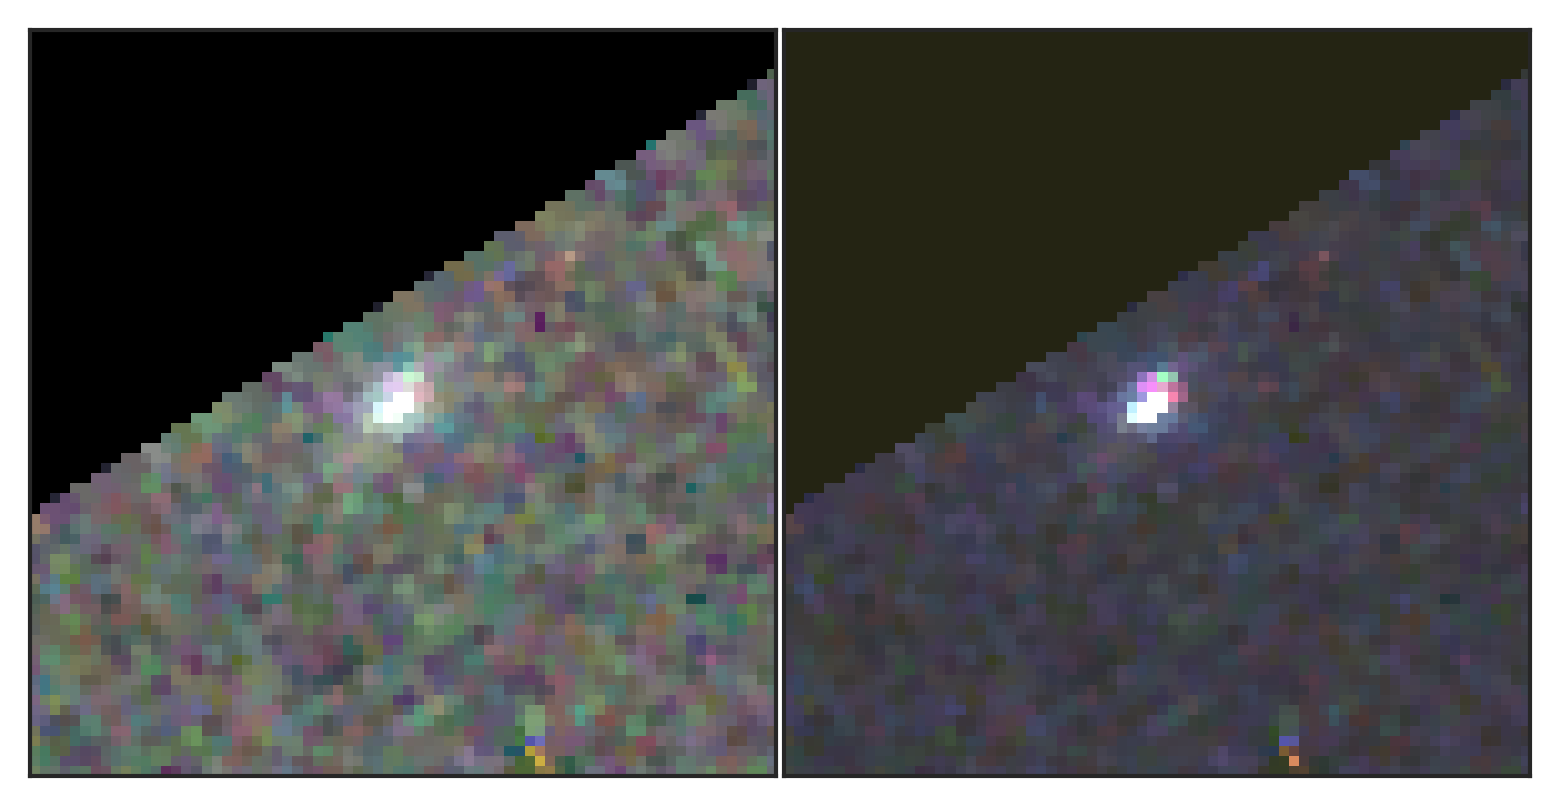

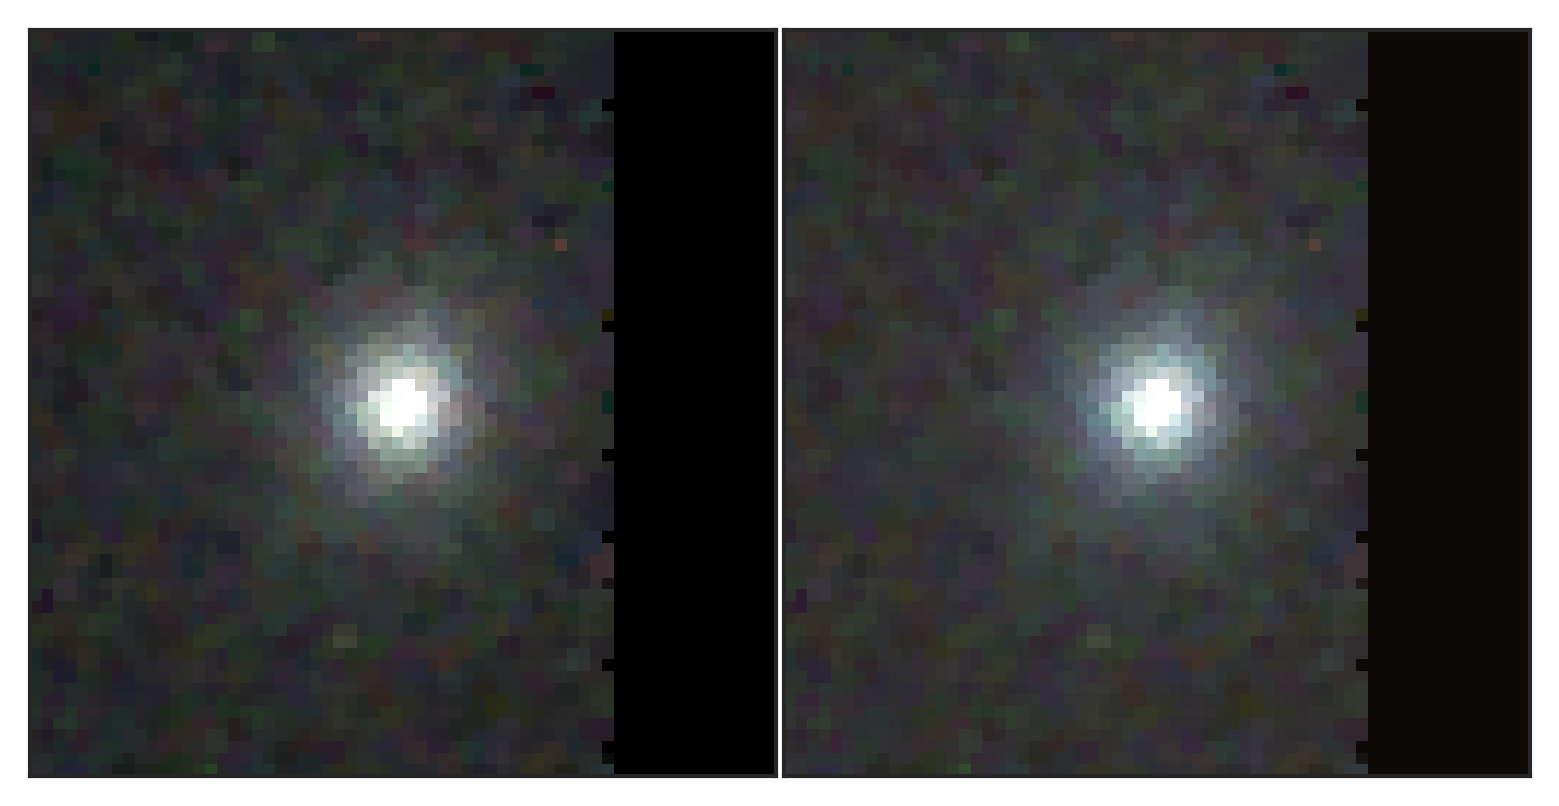

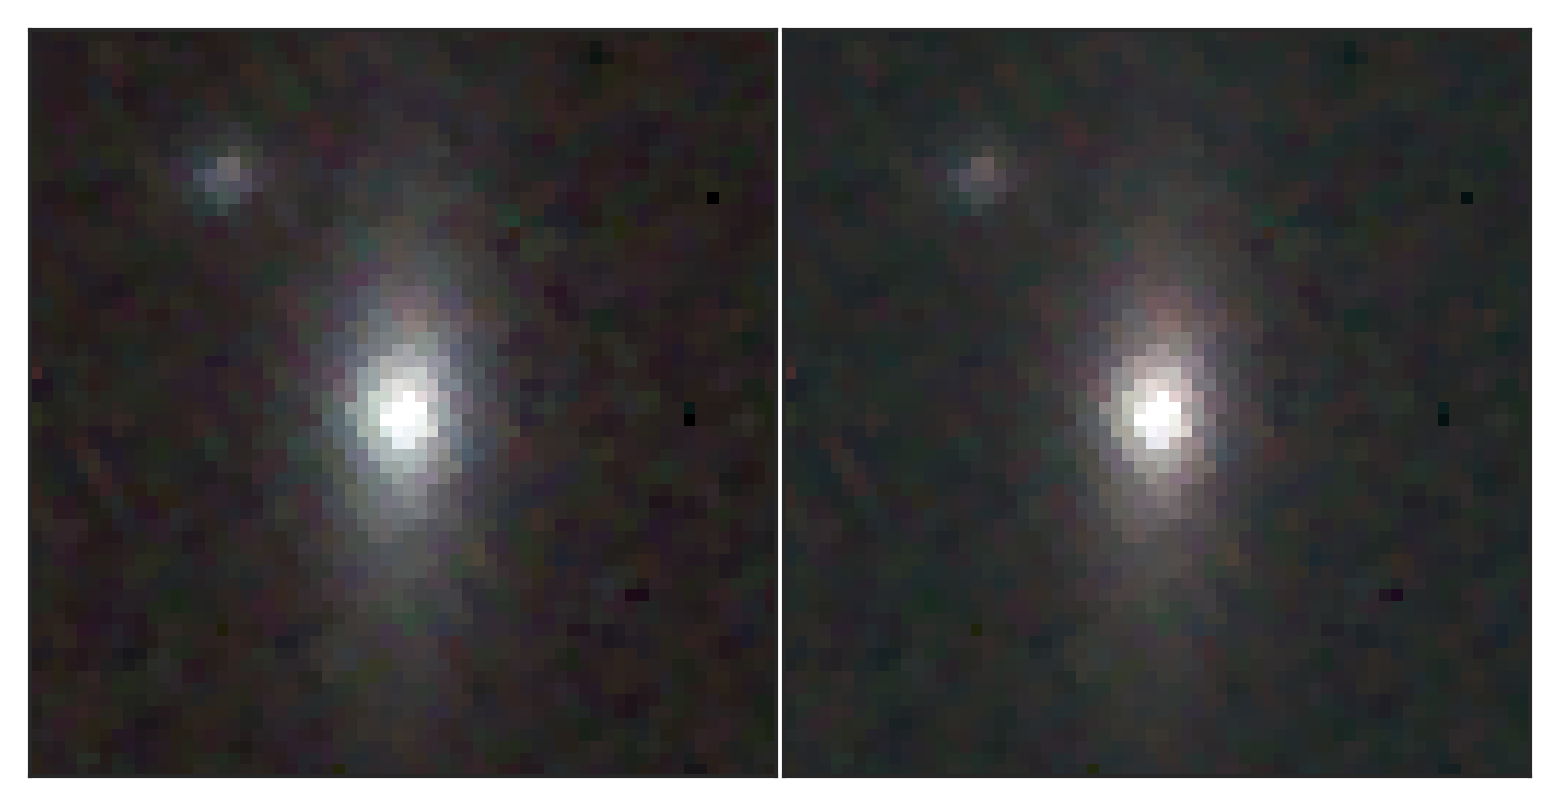

In [6]:
# make test images
for src_i in range(len(cat_df['id_str'][:5])):
    id_str = str(cat_df['id_str'][src_i])
    # print(id_str)
    make_color_subject(id_str, colour_cutout_save_dir, panel1_type='arcsinh_desaturated', panel2_type='mtf_desaturated')

In [7]:
num_subjects = 200 # how many subjects do you want to create?
# num_subjects = len(cat_df['id_str']) # uncomment this to create subjects for all selected sources 
for src_i in trange(num_subjects):
    id_str = str(cat_df['id_str'][src_i])
    save_path_full = subject_png_save_dir + id_str + '-composite.png' 

    
    
    if not os.path.isfile(save_path_full):
        # make_color_subject(id_field, cutout_loc=cutout_loc, save_path=save_path_full, panel1_type='arcsinh_desaturated', panel2_type='mtf_desaturated')
        make_color_subject(id_str, colour_cutout_save_dir, save_path_full, panel1_type='arcsinh_desaturated', panel2_type='mtf_desaturated')

    if src_i==0:
        print('HEY! You are about to create',num_subjects,'images and save them to',save_path_full)
        print('The first image was created and saved to',save_path_full)
        print('Are we happy with it?')
        confirm = input('Proceed? (y/n): ').strip().lower()

        if confirm != 'y':
            print('Exiting')

  0%|          | 0/200 [00:00<?, ?it/s]

HEY! You are about to create 200 images and save them to /teams/gz-roman/10012026-test-subjects_pngs/0-composite.png
The first image was created and saved to /teams/gz-roman/10012026-test-subjects_pngs/0-composite.png
Are we happy with it?


Proceed? (y/n):  y


100%|██████████| 200/200 [00:32<00:00,  6.16it/s]


# Make Single band images

In [8]:
def make_single_band_image(source_id, bands, png_locs, save_path = '', add_bands = False):
    """
    Make a single band image from the cutout data.
    Args:
        id_field (str): The ID field of the cutout data.
        save_path (str): The path to save the figure. If empty, the figure will not be saved. If given, the figure won't be shown inline.
        add_bands (bool): Whether to add band labels to the images.
    """
    PNG_imgs = {}

    for png_loc,band in zip(png_locs,bands):

        band_img_locs = png_locs + source_id
        PNG_imgs[band] = np.array(Image.open(band_img_locs+f'_{band}.png'))


    fig, axs = plt.subplots(figsize=(5,5), sharex=True, sharey=True, ncols=2, nrows=2)
    ax = axs.ravel()

    for i in range(len(bands)):
        ax[i].imshow(PNG_imgs[bands[i]])
        if add_bands:
            ax[i].text(0, 1, bands[i], fontsize='small', color='#00979D', ha='left', va='top', transform=ax[i].transAxes)

    ax[i].set_xticks([])
    ax[i].set_yticks([])

    
    if save_path:
        if 'png' in save_path:
                plt.savefig(save_path, bbox_inches='tight', transparent=True)
        else:
                plt.savefig(save_path, bbox_inches='tight', pil_kwargs={'quality': 95})
        plt.close(fig)

    plt.show()

In [9]:
cat_df.columns


Index(['id_str', 'asdf_loc_f106', 'asdf_loc_f129', 'asdf_loc_f158',
       'ra_centroid_f106', 'dec_centroid_f106', 'kron_abmag_f106',
       'kron_radius_f106', 'fluxfrac_radius_50_f106', 'segment_area_f106',
       'is_extended_f106', 'semimajor_f106', 'semiminor_f106',
       'ra_centroid_f129', 'dec_centroid_f129', 'kron_abmag_f129',
       'kron_radius_f129', 'fluxfrac_radius_50_f129', 'segment_area_f129',
       'is_extended_f129', 'semimajor_f129', 'semiminor_f129',
       'ra_centroid_f158', 'dec_centroid_f158', 'kron_abmag_f158',
       'kron_radius_f158', 'fluxfrac_radius_50_f158', 'segment_area_f158',
       'is_extended_f158', 'semimajor_f158', 'semiminor_f158', 'skycell'],
      dtype='str')

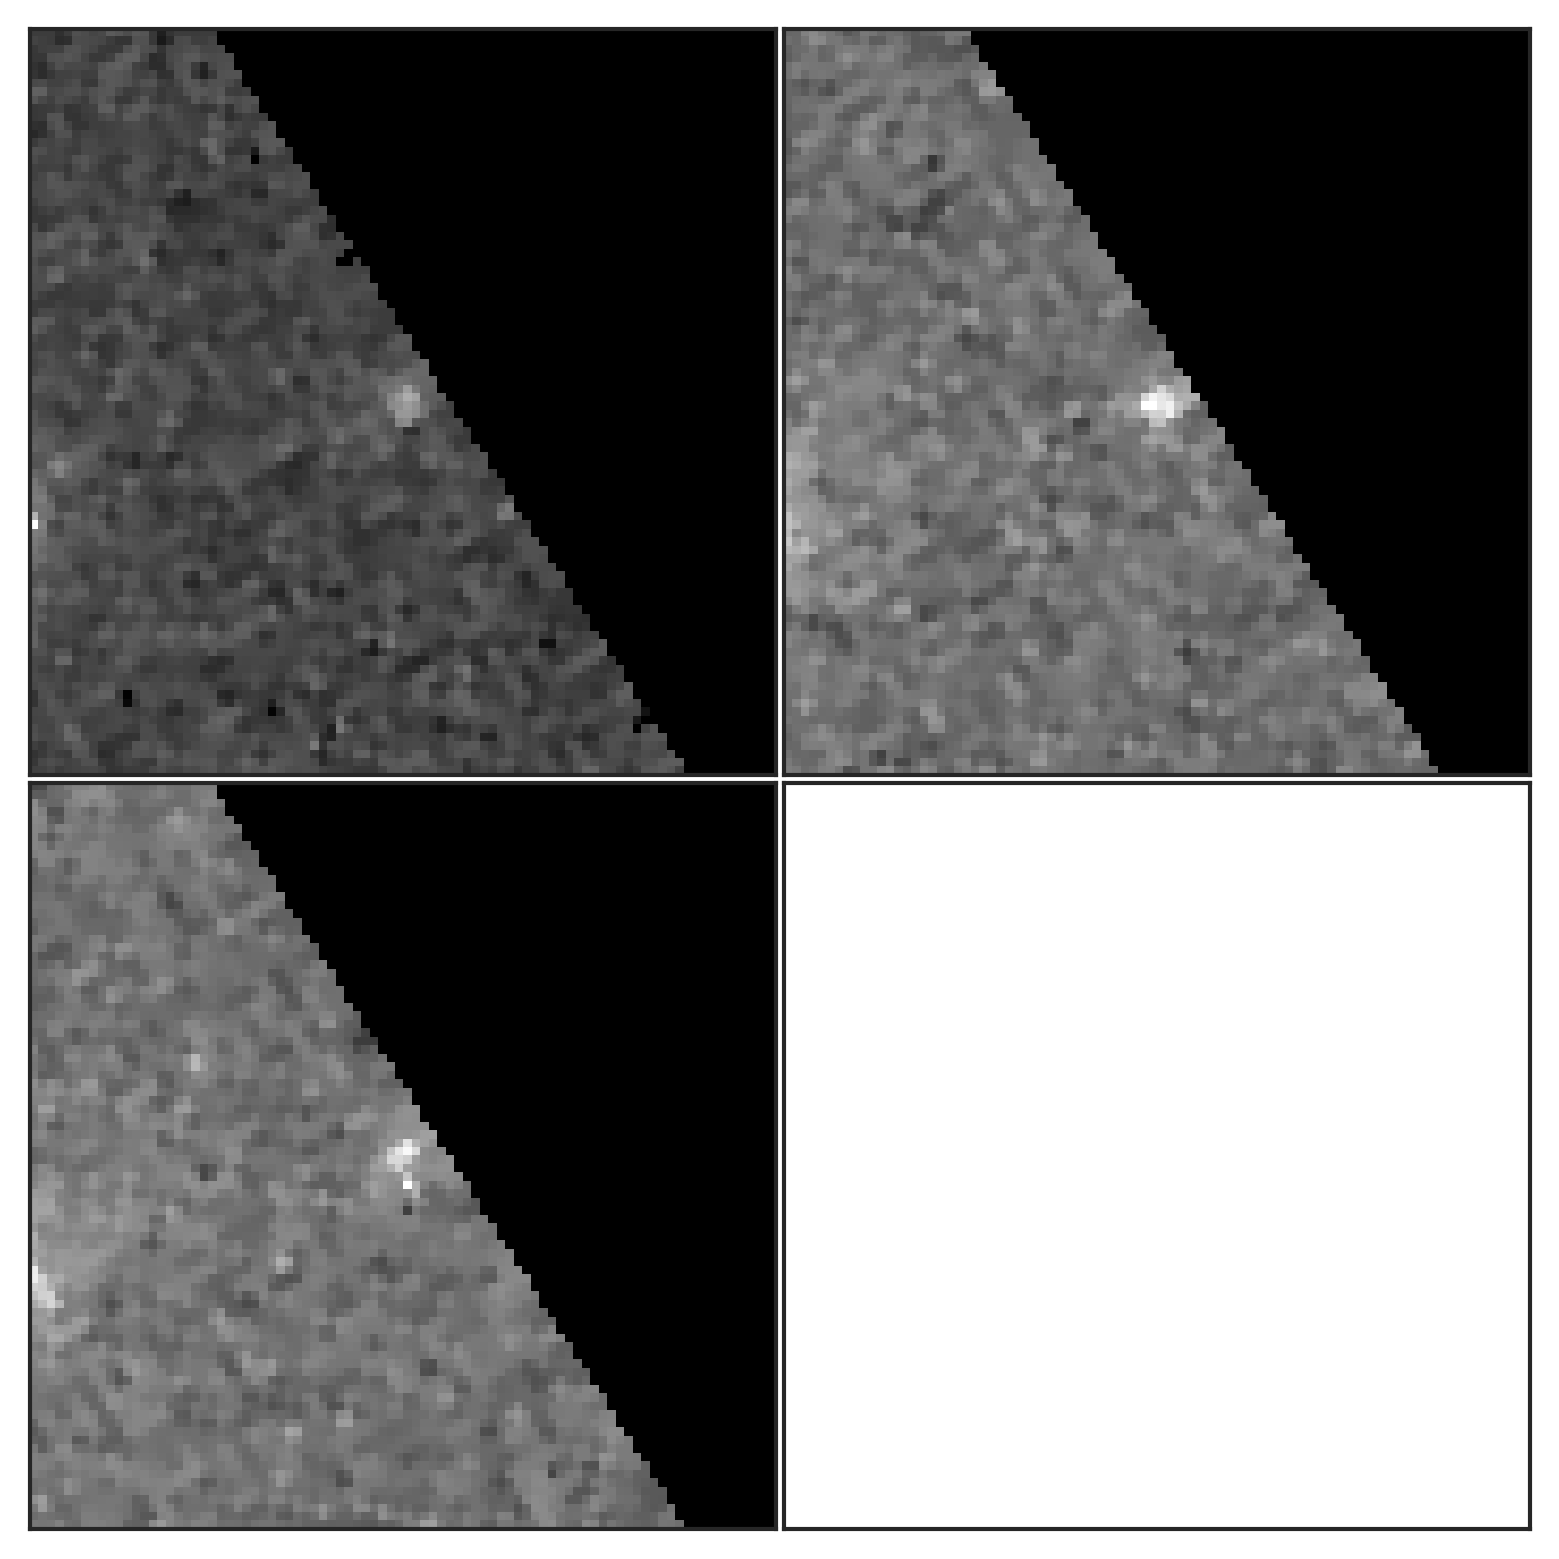

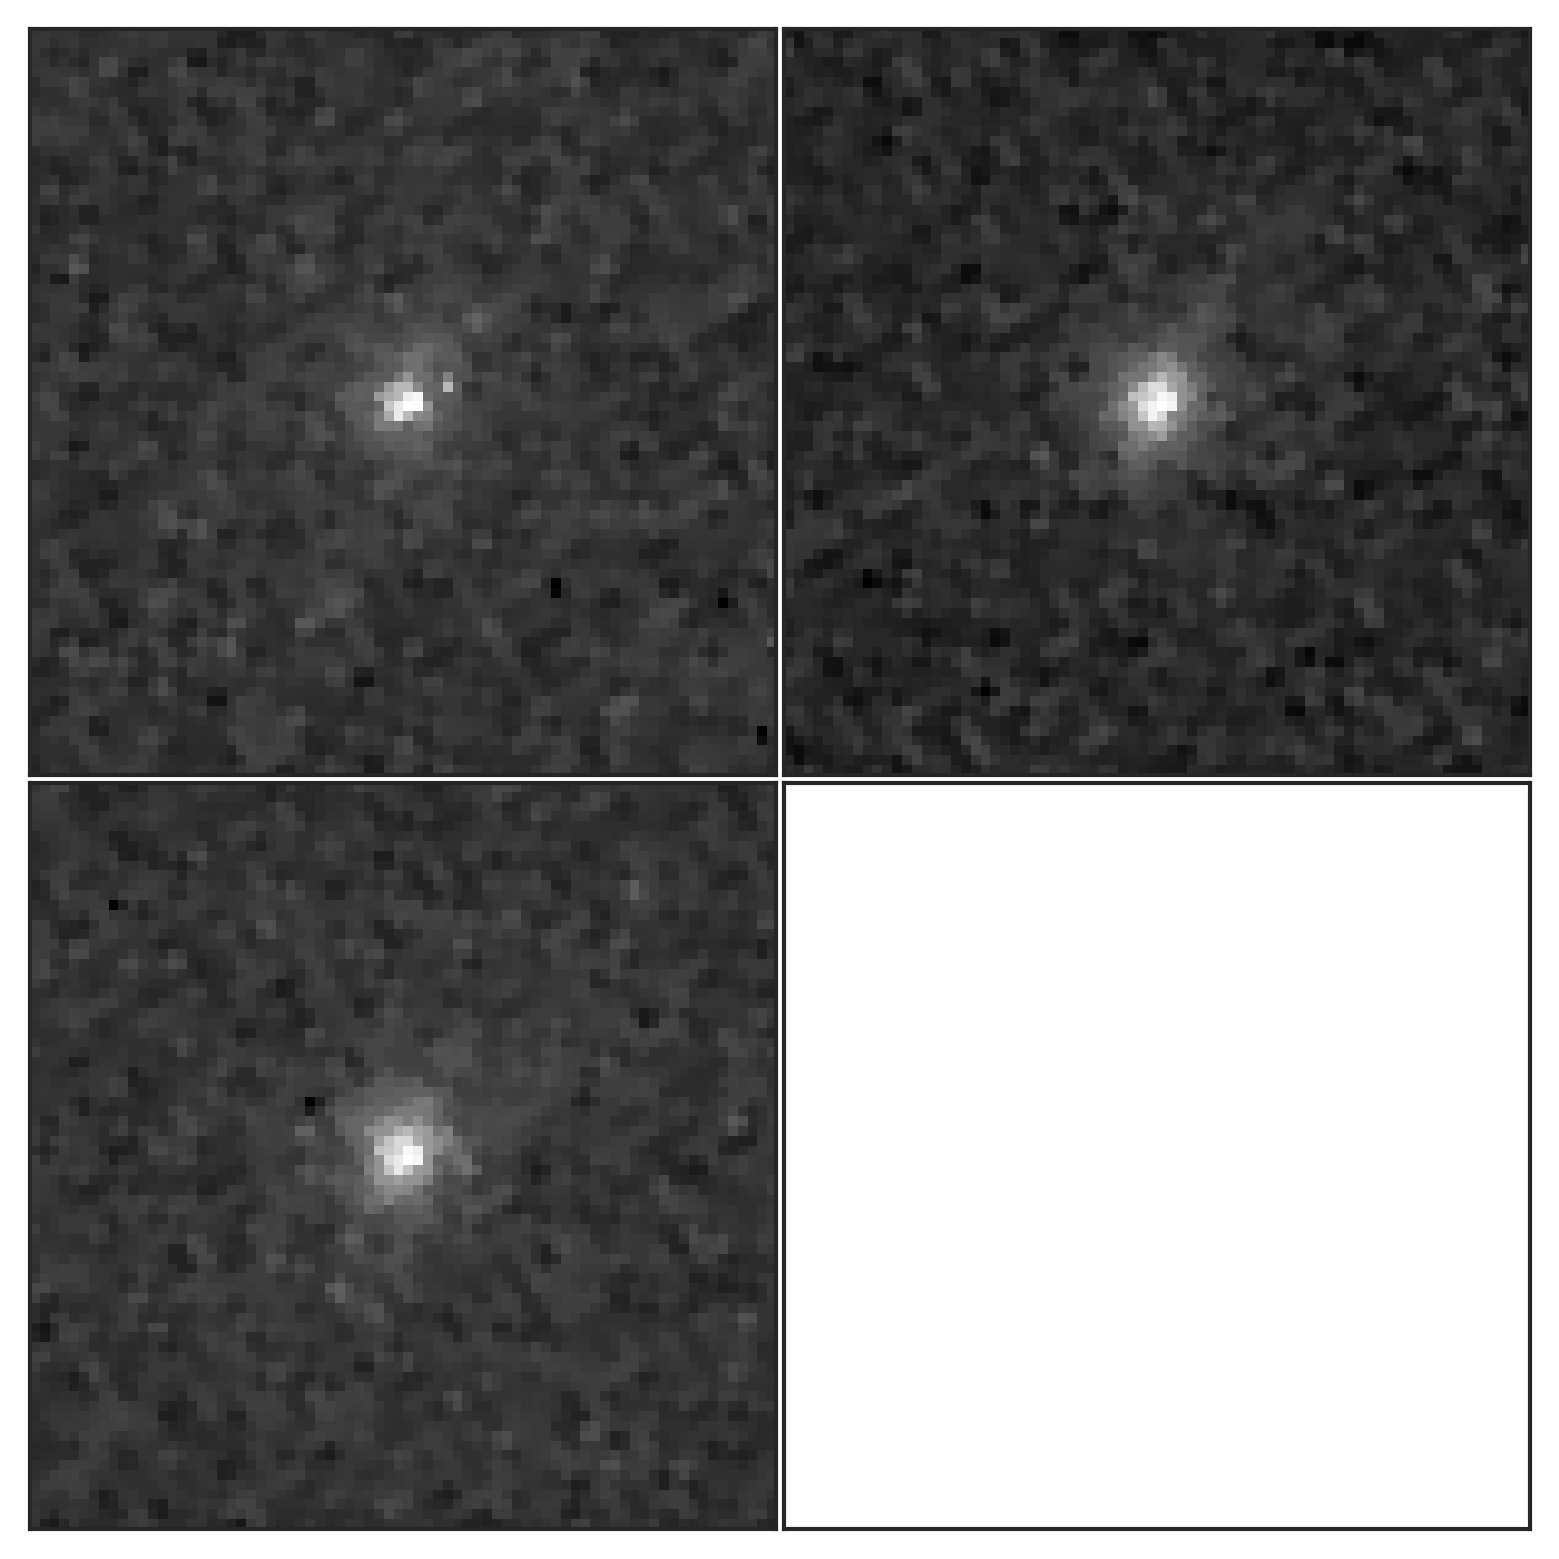

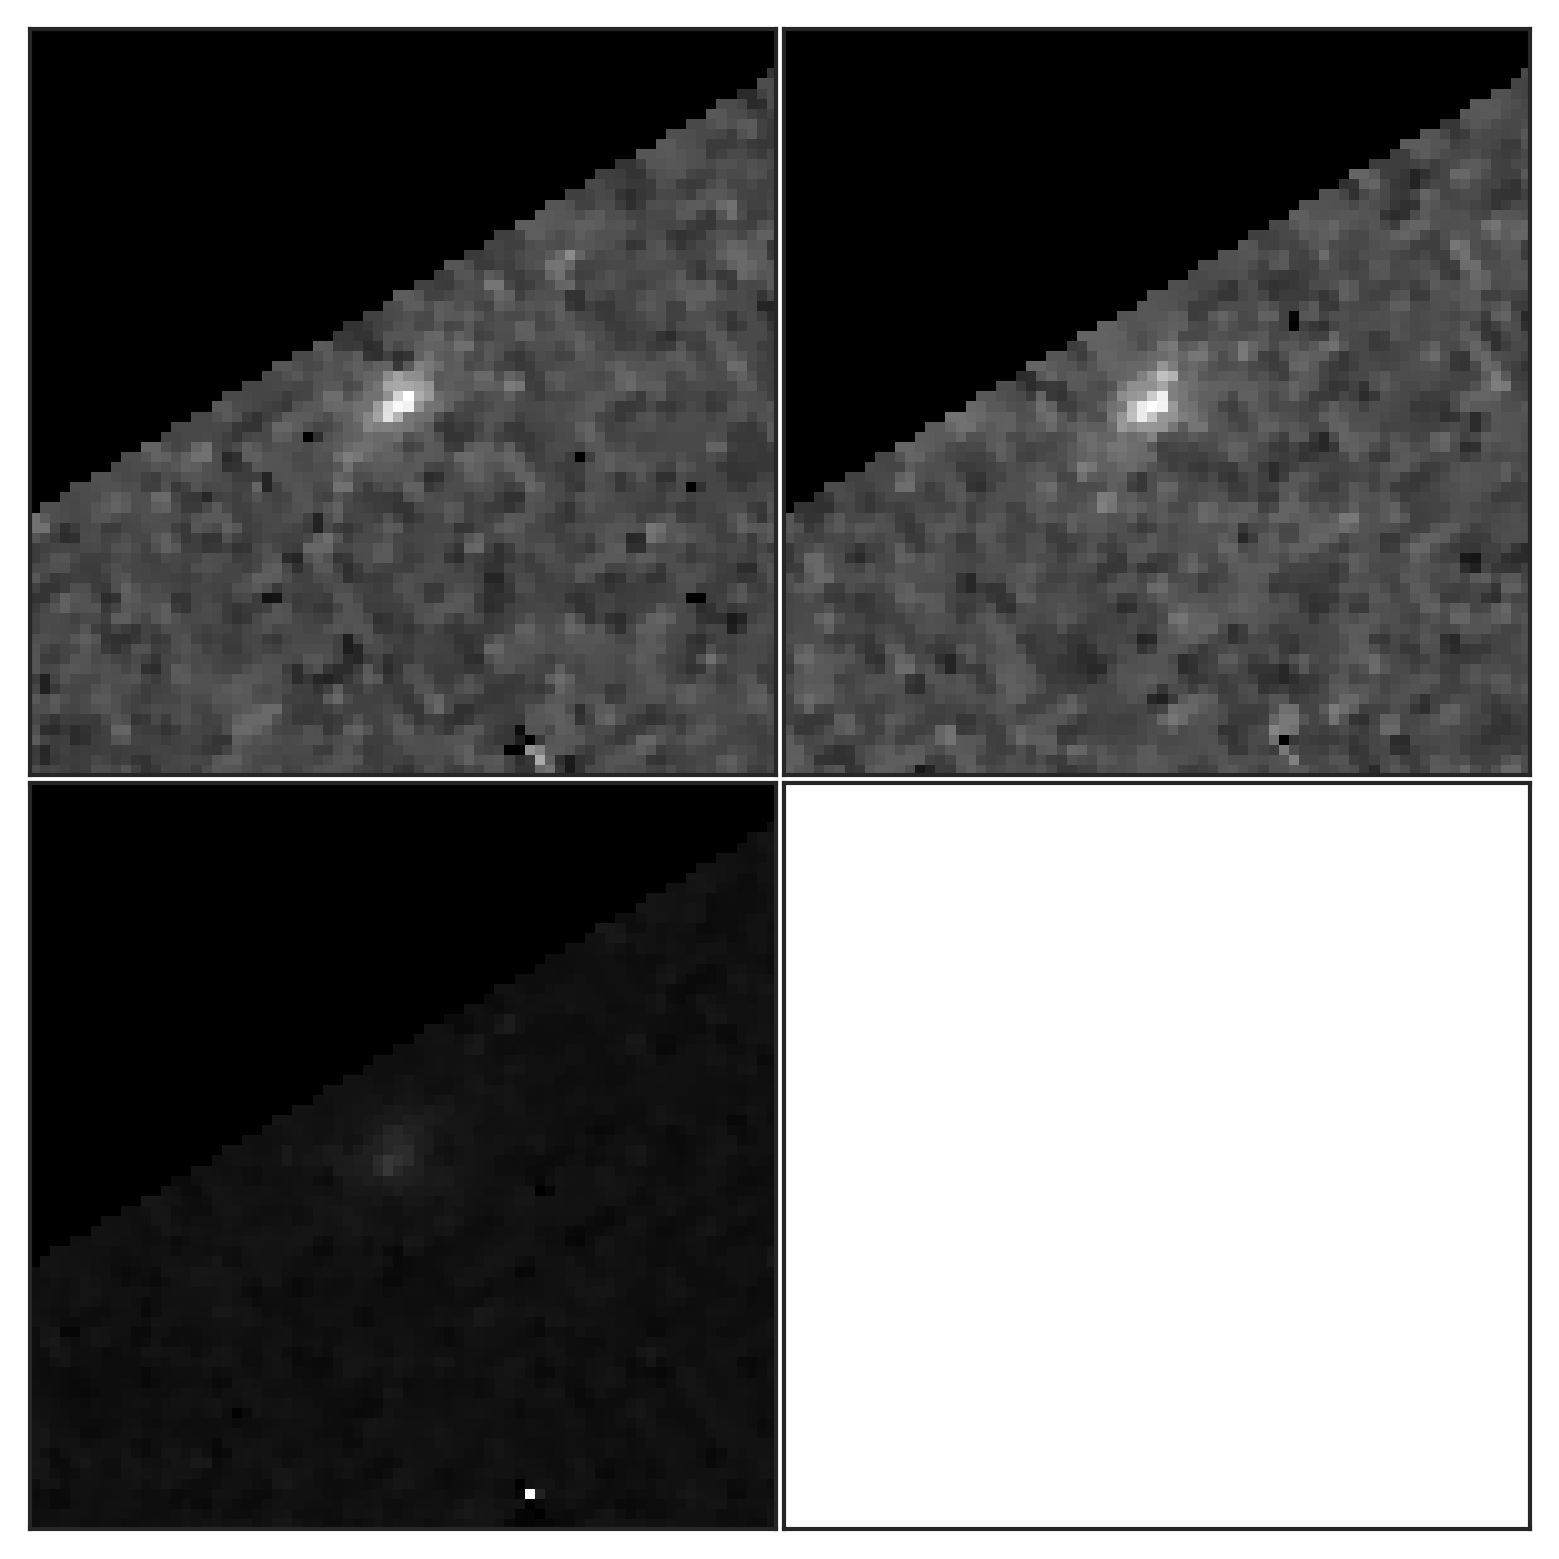

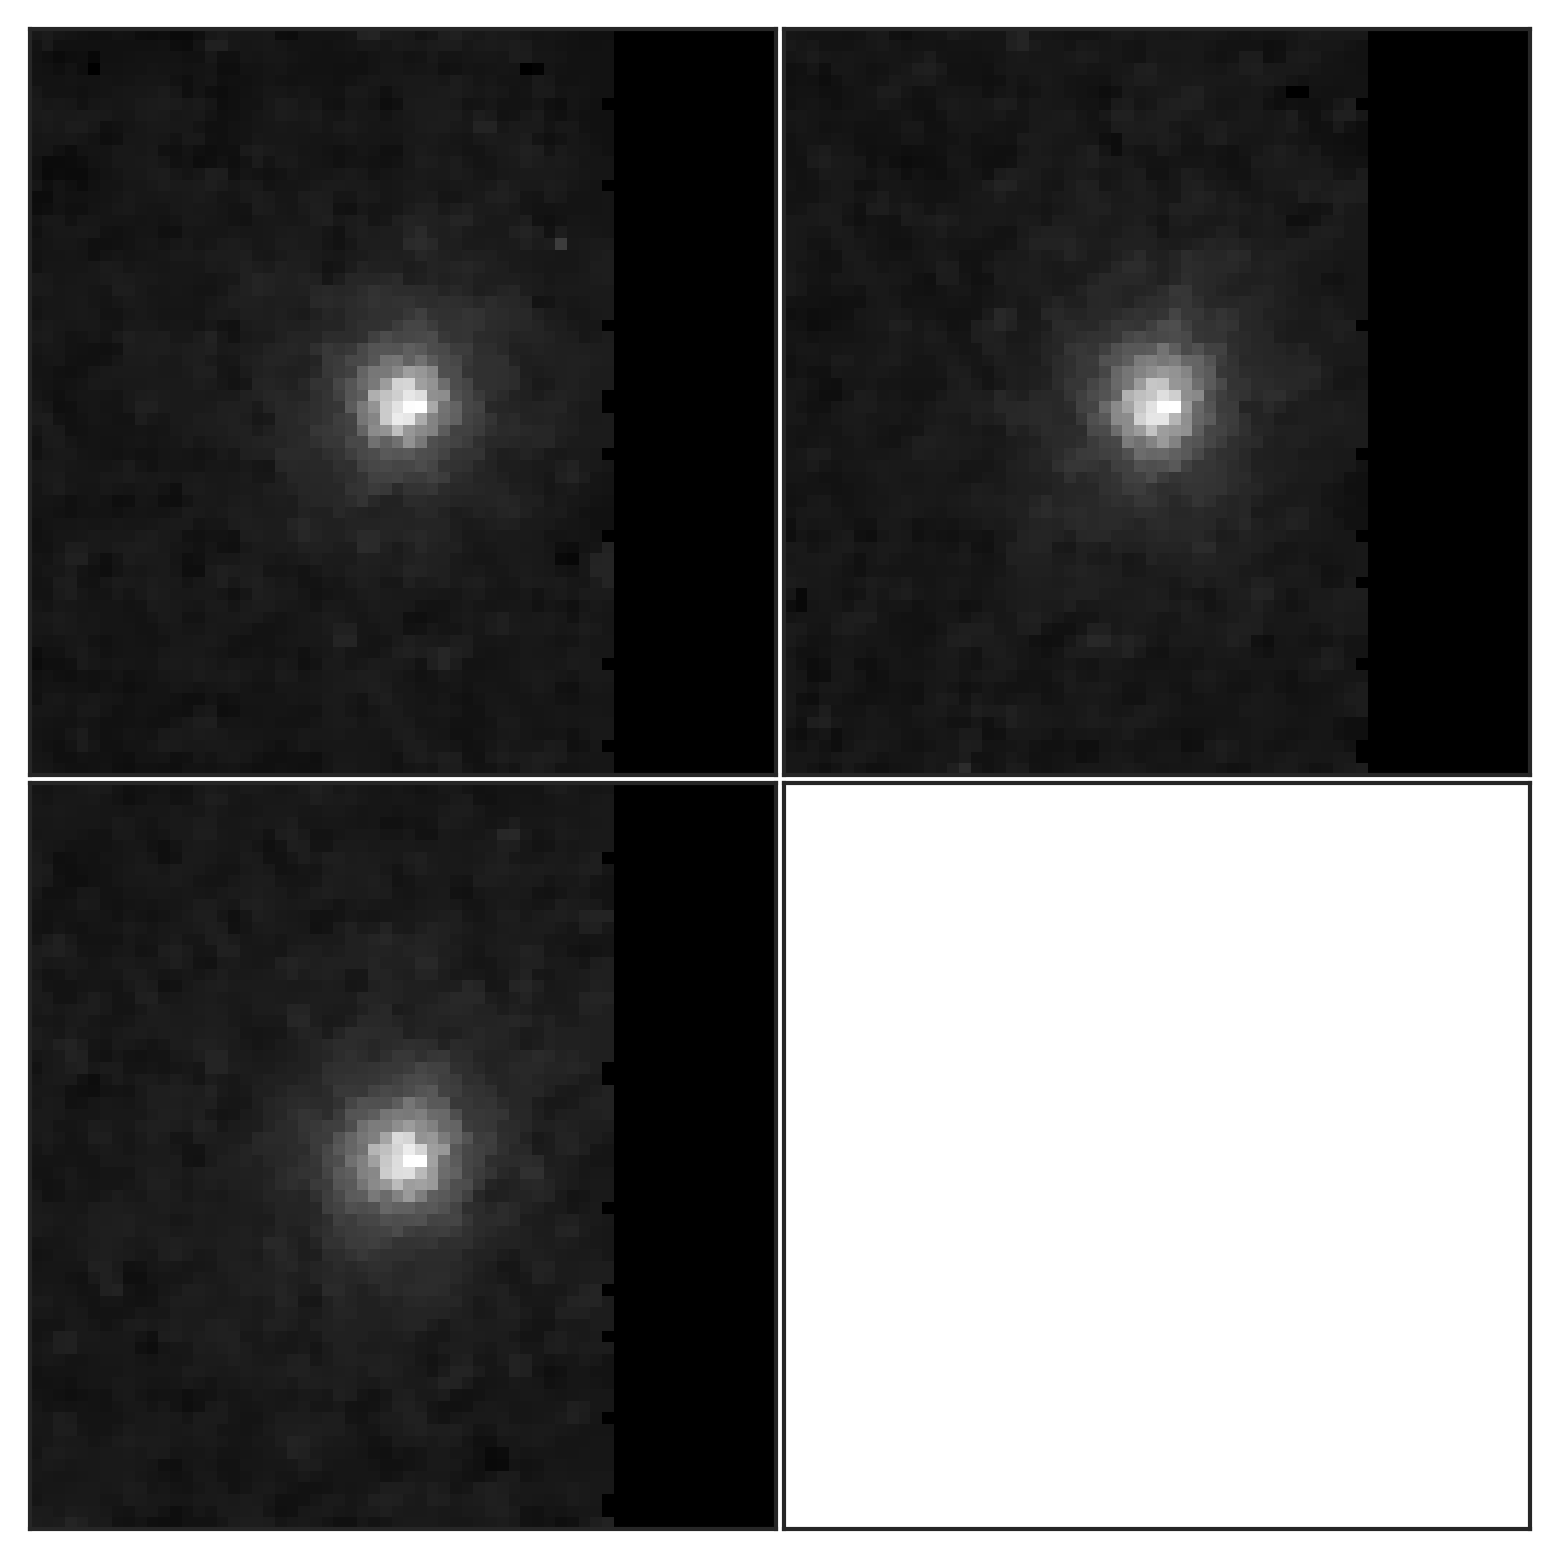

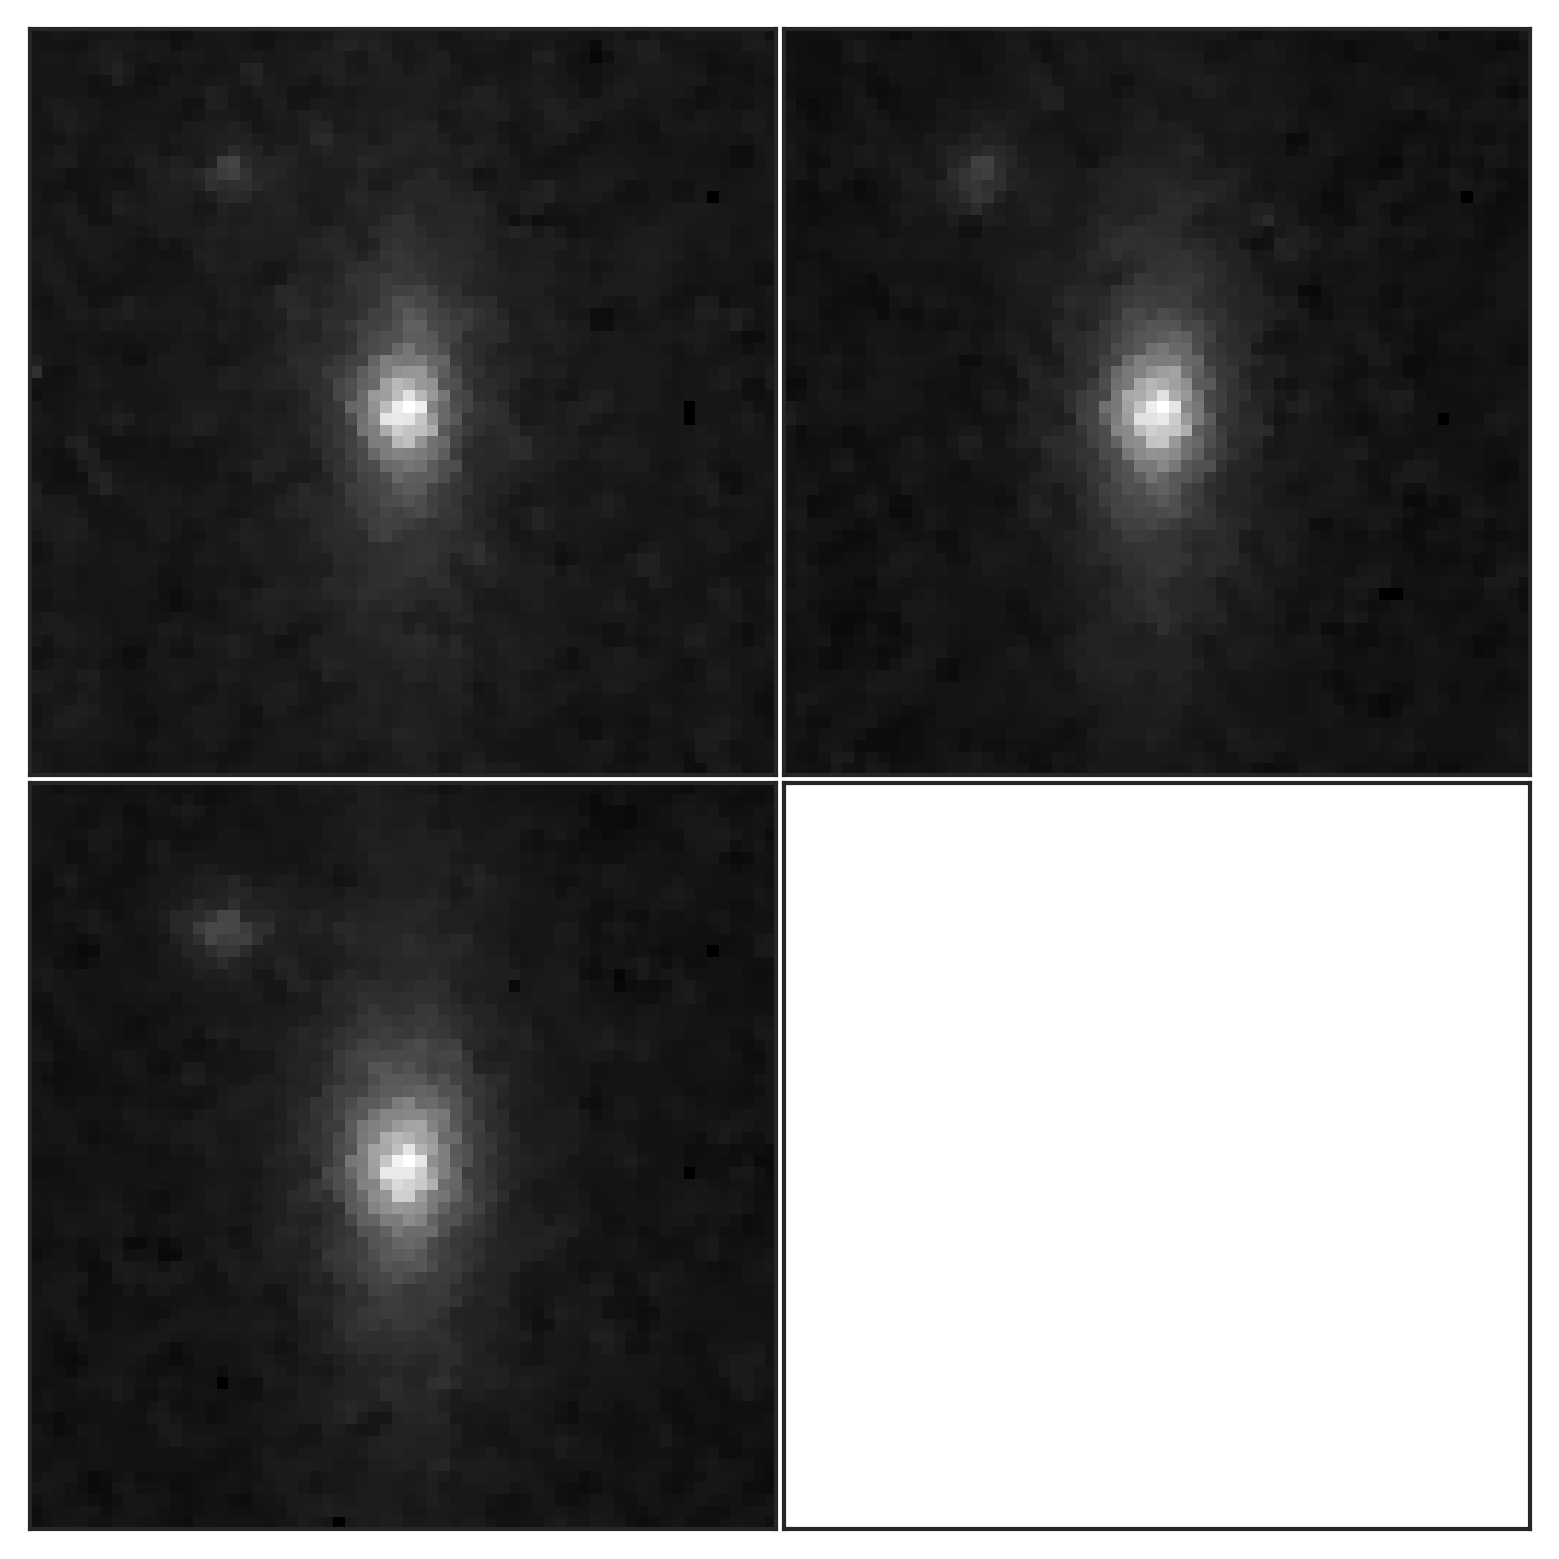

In [10]:
# make some test images

for src_i in range(len(cat_df['id_str'][:5])):
    id_str = str(cat_df['id_str'][src_i])

    make_single_band_image(id_str, bands, cutout_save_dir, save_path = '', add_bands = False)

In [11]:
for src_i in trange(num_subjects):
    id_str = str(cat_df['id_str'][src_i])
    # save_path_full = subject_png_save_dir + id_str + '-composite.png'
    save_path_full = subject_png_save_dir + id_str + '-single_band.png'
    
    if not os.path.isfile(save_path_full):
        make_single_band_image(id_str, bands, cutout_save_dir, save_path=save_path_full)

    if src_i==0:
        print('HEY! You are about to create',num_subjects,'images and save them to ',save_path_full)
        print('The first image was created and saved to ', save_path_full)
        print('Are we happy with it?')
        confirm = input('Proceed? (y/n): ').strip().lower()

        if confirm != 'y':
            print('Exiting')
  

  0%|          | 0/200 [00:00<?, ?it/s]

HEY! You are about to create 200 images and save them to  /teams/gz-roman/10012026-test-subjects_pngs/0-single_band.png
The first image was created and saved to  /teams/gz-roman/10012026-test-subjects_pngs/0-single_band.png
Are we happy with it?


Proceed? (y/n):  y


100%|██████████| 200/200 [01:05<00:00,  3.08it/s]
